# 자연어 처리 4일차 (2) — RNN 으로 IMDB 영화 리뷰 감성 분석 (PyTorch)

수업 필기 `nlp_실습07` 을 **실행 가능하도록 정리하고, 필기에서 멈춘 뒤(모델 · 학습 · 평가)까지 이어서 완성한 노트**입니다.
(교재 `자연어처리` 교재v1 **p.73~74** — IMDB 영화 리뷰 감성 분석 실습 · 모델 구성과 데이터 흐름)

```
리뷰(단어 번호 470개) → Embedding(10000, 32) → RNN(32 → 16) → 마지막 h (16) → Linear(16 → 1) → 긍정 확률
```

- RNN 셀 계산 · 가중치 모양 · BPTT 는 [`matmul_rnn_cell.ipynb`](./matmul_rnn_cell.ipynb) 에 있습니다.
- 원본에서 고친 부분은 **📝 고친 부분** 으로 적었습니다.

## 0. 설치 · 실행 방법

| 패키지 | 이 노트에서 쓰는 것 | 설치 |
|---|---|---|
| `keras` | IMDB 데이터 받기 `keras.datasets.imdb` · 길이 맞추기 `keras.utils.pad_sequences` | Colab 기본 포함 (TensorFlow 와 함께) · 로컬은 `pip install keras` — **TensorFlow 없이** PyTorch 를 백엔드로 쓴다 |
| `torch` | 모델 · 학습 | Colab 기본 포함 · 로컬은 `pip install torch` |
| `numpy` · `matplotlib` | 통계 · 그래프 | Colab 기본 포함 |

**실행 순서** : 맨 위부터 **[런타임] → [모두 실행]**. 첫 실행 때 IMDB(17MB)와 단어 사전(1.6MB)을 자동으로 받는다.
**시간** : CPU 로 에폭당 약 10초(이 노트 실행 기준 · 컴퓨터마다 다름), 전체 약 5분. Colab GPU(**[런타임] → [런타임 유형 변경] → T4**)면 더 빠르다.

In [1]:
# ① 설치 (로컬에서 처음 한 번 — Colab 은 기본 포함)
# !pip install -q keras torch

In [2]:
# 그래프 한글 폰트 설정 (운영체제별)
import platform
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
# Colab(리눅스) : !apt-get install -y fonts-nanum 후 런타임 재시작 → plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

In [3]:
import os
os.environ.setdefault('KERAS_BACKEND', 'torch')   # TensorFlow 가 없어도 keras 의 데이터 도구를 쓸 수 있게
import time
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import keras
keras.utils.disable_interactive_logging()          # 다운로드 진행 막대 숨기기

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('사용 중인 디바이스 :', device)

사용 중인 디바이스 : cpu


> **📝 고친 부분 (원본 cell 1~3)**
> - `import tensorflow as tf` 를 두 번 → 데이터 받기와 `pad_sequences` 에만 쓰므로 **`keras`** 하나로 (Colab 의 keras 는 TensorFlow 위에서, 로컬은 PyTorch 위에서 그대로 동작)
> - 쓰지 않는 `from torch.cuda import is_available` · `from pygments import token`(자동 완성으로 끼어든 줄) 삭제
> - 실행할 때마다 결과가 바뀌지 않게 `SEED` 고정

## 1. 데이터 받기 — 단어 번호로 된 리뷰 (교재 p.73)

In [4]:
NUM_WORDS = 10000                     # 자주 나오는 단어 1만 개만 사전에 (나머지는 2 = OOV)
(X_train_raw, y_train), (X_test_raw, y_test) = keras.datasets.imdb.load_data(num_words=NUM_WORDS)
print('학습 :', len(X_train_raw), '| 평가 :', len(X_test_raw), '| 긍정 비율', y_train.mean(), y_test.mean())
print('첫 리뷰 앞 12개 번호 :', X_train_raw[0][:12], '| 정답 :', y_train[0])

학습 : 25000 | 평가 : 25000 | 긍정 비율 0.5 0.5
첫 리뷰 앞 12개 번호 : [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468] | 정답 : 1


In [5]:
# 번호 → 단어로 되돌려 보기 (사전 번호는 3 칸 밀려 있다 : 0 패딩 · 1 시작 · 2 OOV · 3 미사용)
word_index = keras.datasets.imdb.get_word_index()
index_word = {i + 3: w for w, i in word_index.items()}
index_word.update({0: '<pad>', 1: '<start>', 2: '<unk>', 3: '<unused>'})
decode = lambda ids: ' '.join(index_word.get(i, '?') for i in ids)

print(decode(X_train_raw[0][:40]), '...')

<start> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <unk> is an amazing actor and now the same being director <unk> father came ...


`<unk>`(2)는 사전 1만 개 밖의 드문 단어다. 원본 주석의 `0 패딩 · 1 시작 · 2 없는 단어 · 3 사용 안 함` 은 **맞다** (`index_from=3` 이라 실제 단어는 4번부터).

## 2. 리뷰 길이 — `max_len` 정하기

평균 238.7 | 중앙값 · 75% · 90% · 95% · 최대 : [ 178.  291.  467.  610. 2494.]
470 단어보다 긴 리뷰 : 9.8% → 앞부분이 잘린다


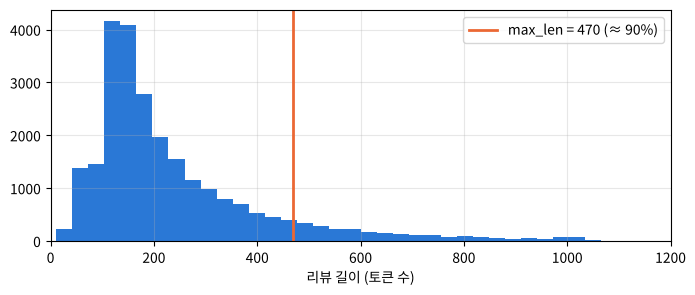

In [6]:
lengths = np.array([len(r) for r in X_train_raw])          # 25,000개 전체를 출력하지 않고 배열로
q = np.percentile(lengths, [50, 75, 90, 95, 100])
print('평균', lengths.mean().round(1), '| 중앙값 · 75% · 90% · 95% · 최대 :', q)

MAX_LEN = 470
print(f'{MAX_LEN} 단어보다 긴 리뷰 : {(lengths > MAX_LEN).mean():.1%} → 앞부분이 잘린다')

import matplotlib.pyplot as plt
plt.figure(figsize=(8, 3))
plt.hist(lengths, bins=80, color='#2a78d6')
plt.axvline(MAX_LEN, color='#eb6834', lw=2, label=f'max_len = {MAX_LEN} (≈ 90%)')
plt.xlim(0, 1200); plt.xlabel('리뷰 길이 (토큰 수)'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

> **📝 고친 부분 (원본 cell 8~9)**
> - `token_lenth` 오타 → `lengths`, 길이 **25,000개를 통째로 출력** → 통계 · 히스토그램으로
> - `from pygments import token` (쓰지 않는 줄) 삭제
> - 90% 분위수 467 → `max_len = 470` 은 원본과 같게 유지

## 3. 길이 맞추기 — `pad_sequences` 의 기본은 **앞쪽**

In [7]:
X_train = keras.utils.pad_sequences(X_train_raw, maxlen=MAX_LEN)     # padding='pre', truncating='pre' (기본값)
X_test = keras.utils.pad_sequences(X_test_raw, maxlen=MAX_LEN)
print('학습 :', X_train.shape, '| 평가 :', X_test.shape)

short = X_train_raw[0]
print(f'\n짧은 리뷰({len(short)}개) → 앞에 0 을 {MAX_LEN - len(short)}개 채움 :', X_train[0][:5], '...', X_train[0][-5:])
long_i = int(np.argmax(lengths))
print(f'가장 긴 리뷰({lengths[long_i]}개) → 앞 {lengths[long_i] - MAX_LEN}개를 버리고 끝 {MAX_LEN}개만 :',
      (X_train[long_i] == np.array(X_train_raw[long_i][-MAX_LEN:])).all())

학습 : (25000, 470) | 평가 : (25000, 470)

짧은 리뷰(218개) → 앞에 0 을 252개 채움 : [0 0 0 0 0] ... [  16 5345   19  178   32]
가장 긴 리뷰(2494개) → 앞 2024개를 버리고 끝 470개만 : True


RNN 은 **마지막 은닉 상태**로 예측하므로 실제 단어가 **끝쪽에** 붙어 있어야 한다 → `padding='pre'`(기본값)가 맞다. 뒤에 0 을 붙이면(`'post'`) 마지막 수백 칸이 전부 패딩이라 리뷰 내용이 사라진다(§7 실험).

## 4. 텐서 · 검증용 나누기 · DataLoader

In [8]:
# 학습 25,000 → 학습 20,000 + 검증 5,000 (평가용 25,000 은 마지막에 한 번만)
perm = np.random.permutation(len(X_train))
tr, va = perm[:20000], perm[20000:]

def to_ds(X, y):
    return TensorDataset(torch.LongTensor(X), torch.FloatTensor(y))   # 단어 번호는 정수, 정답은 실수(BCE 손실)

train_loader = DataLoader(to_ds(X_train[tr], y_train[tr]), batch_size=250, shuffle=True)
val_loader = DataLoader(to_ds(X_train[va], y_train[va]), batch_size=1000)
test_loader = DataLoader(to_ds(X_test, y_test), batch_size=1000)
print('배치 수 — 학습', len(train_loader), '· 검증', len(val_loader), '· 평가', len(test_loader))

배치 수 — 학습 80 · 검증 5 · 평가 25


> **📝 고친 부분 (원본 cell 12~13)**
> - 주석 `X데이터(train,text)` · `형변화` → **test** · 형변환
> - 데이터 전체를 미리 `.to(device)` → GPU 메모리에 다 올리지 않고 **배치마다** 옮긴다(학습 루프 안)
> - 평가용 25,000개로 학습 중 성능을 보면 평가 데이터에 맞춰 고르게 된다 → 학습 데이터에서 **검증 5,000개**를 떼어 에폭 선택에 쓰고, 평가용은 마지막에 한 번만

## 5. 모델 — Embedding → RNN → Linear (교재 p.74)

In [9]:
class SentimentRNN(nn.Module):
    def __init__(self, vocab=NUM_WORDS, emb_dim=32, hidden=16):
        super().__init__()
        self.embedding = nn.Embedding(vocab, emb_dim)               # 단어 번호 → (32,) 벡터, 처음엔 무작위
        self.rnn = nn.RNN(emb_dim, hidden, batch_first=True)        # (배치, 470, 32) → h_n (1, 배치, 16)
        self.fc = nn.Linear(hidden, 1)                              # 16 → 1 (긍정 점수, logit)

    def forward(self, x):
        output, h_n = self.rnn(self.embedding(x))
        return self.fc(h_n[-1]).squeeze(1)                          # 마지막 시점만 사용

model = SentimentRNN().to(device)
print(model)
for name, p in model.named_parameters():
    print(f'  {name:22s} {tuple(p.shape)}')
print('가중치 총', sum(p.numel() for p in model.parameters()), '개')

SentimentRNN(
  (embedding): Embedding(10000, 32)
  (rnn): RNN(32, 16, batch_first=True)
  (fc): Linear(in_features=16, out_features=1, bias=True)
)
  embedding.weight       (10000, 32)
  rnn.weight_ih_l0       (16, 32)
  rnn.weight_hh_l0       (16, 16)
  rnn.bias_ih_l0         (16,)
  rnn.bias_hh_l0         (16,)
  fc.weight              (1, 16)
  fc.bias                (1,)
가중치 총 320817 개


출력층에 sigmoid 를 넣지 않고 `BCEWithLogitsLoss`(sigmoid + BCE 를 한 번에, 수치적으로 안정)를 쓴다. 확률이 필요할 때만 `torch.sigmoid`.

## 6. 학습 · 검증

In [10]:
def run_epoch(model, loader, optimizer=None):
    train = optimizer is not None
    model.train(train)
    total, loss_sum, correct = 0, 0.0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            loss_sum += loss.item() * len(yb)
            correct += ((logits > 0).float() == yb).sum().item()
            total += len(yb)
    return loss_sum / total, correct / total

criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)
EPOCHS = 15
history, best = [], (0, None, 0)
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc = run_epoch(model, train_loader, optimizer)
    va_loss, va_acc = run_epoch(model, val_loader)
    history.append((tr_loss, tr_acc, va_loss, va_acc))
    if va_acc > best[0]:
        best = (va_acc, {k: v.clone() for k, v in model.state_dict().items()}, epoch)
    print(f'에폭 {epoch:2d}  학습 손실 {tr_loss:.4f} 정확도 {tr_acc:.3f} | 검증 손실 {va_loss:.4f} 정확도 {va_acc:.3f}  ({time.time() - t0:.0f}초)')
print(f'\n검증 정확도가 가장 높은 에폭 : {best[2]} ({best[0]:.3f})')

에폭  1  학습 손실 0.6979 정확도 0.522 | 검증 손실 0.6869 정확도 0.547  (12초)


에폭  2  학습 손실 0.6778 정확도 0.573 | 검증 손실 0.6741 정확도 0.577  (7초)


에폭  3  학습 손실 0.6555 정확도 0.614 | 검증 손실 0.6480 정확도 0.616  (18초)


에폭  4  학습 손실 0.6121 정확도 0.665 | 검증 손실 0.6122 정확도 0.663  (8초)


에폭  5  학습 손실 0.5665 정확도 0.710 | 검증 손실 0.5828 정확도 0.695  (7초)


에폭  6  학습 손실 0.5282 정확도 0.743 | 검증 손실 0.5631 정확도 0.713  (7초)


... (5 outputs left out)

에폭 12  학습 손실 0.3792 정확도 0.845 | 검증 손실 0.4981 정확도 0.778  (9초)


에폭 13  학습 손실 0.4867 정확도 0.801 | 검증 손실 0.7979 정확도 0.623  (9초)


에폭 14  학습 손실 0.5088 정확도 0.757 | 검증 손실 0.5386 정확도 0.745  (7초)


에폭 15  학습 손실 0.4087 정확도 0.827 | 검증 손실 0.5131 정확도 0.765  (7초)

검증 정확도가 가장 높은 에폭 : 12 (0.778)


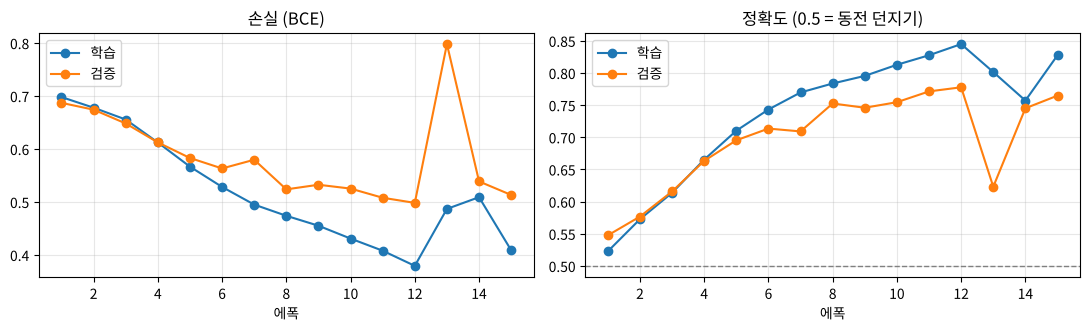

In [11]:
h = np.array(history)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(range(1, EPOCHS + 1), h[:, 0], 'o-', label='학습'); axes[0].plot(range(1, EPOCHS + 1), h[:, 2], 'o-', label='검증')
axes[0].set_title('손실 (BCE)'); axes[0].set_xlabel('에폭'); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(range(1, EPOCHS + 1), h[:, 1], 'o-', label='학습'); axes[1].plot(range(1, EPOCHS + 1), h[:, 3], 'o-', label='검증')
axes[1].axhline(0.5, color='gray', ls='--', lw=1); axes[1].set_title('정확도 (0.5 = 동전 던지기)'); axes[1].set_xlabel('에폭')
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [12]:
model.load_state_dict(best[1])                       # 검증 기준 가장 좋았던 가중치로
test_loss, test_acc = run_epoch(model, test_loader)
print(f'평가용 25,000개 — 손실 {test_loss:.4f} · 정확도 {test_acc:.3f}')
torch.save(model.state_dict(), 'imdb_rnn.pth')       # 가중치만 저장 (불러올 때 torch.load(..., weights_only=True))

평가용 25,000개 — 손실 0.4992 · 정확도 0.776


- 처음 몇 에폭은 정확도가 0.5 근처에서 맴돈다 — 470칸을 지나며 기울기가 약해져(BPTT 기울기 소실) 학습이 느리게 시작된다.
- 중간에 손실이 갑자기 튀는 에폭이 생길 수 있다(이번 실행 : 에폭 13). 같은 $W_h$ 를 수백 번 곱하다 보면 기울기가 **폭주**하기도 해서 — 보통 `torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)` 로 기울기 크기를 자른다. 그래서 마지막 에폭이 아니라 **검증 정확도가 가장 높은 에폭**의 가중치를 쓴다.
- 단순 RNN 은 이 데이터에서 대략 **75~80%** 수준이다(실행마다 조금씩 다름).

## 7. 실험 — 패딩을 뒤에 붙이면?

In [13]:
torch.manual_seed(SEED)
Xp_train = keras.utils.pad_sequences(X_train_raw, maxlen=MAX_LEN, padding='post')
post_loader = DataLoader(to_ds(Xp_train[tr], y_train[tr]), batch_size=250, shuffle=True)
post_val = DataLoader(to_ds(Xp_train[va], y_train[va]), batch_size=1000)

m_post = SentimentRNN().to(device)
opt_post = optim.Adam(m_post.parameters(), lr=1e-3)
for epoch in range(1, 6):
    tl, ta = run_epoch(m_post, post_loader, opt_post)
    vl, vacc = run_epoch(m_post, post_val)
    print(f"[post] 에폭 {epoch}  학습 정확도 {ta:.3f} | 검증 정확도 {vacc:.3f}")
print('\n짧은 리뷰를 post 로 채우면 마지막', MAX_LEN - len(X_train_raw[0]), '칸이 0 →', Xp_train[0][-8:])

[post] 에폭 1  학습 정확도 0.501 | 검증 정확도 0.513


[post] 에폭 2  학습 정확도 0.502 | 검증 정확도 0.493


[post] 에폭 3  학습 정확도 0.509 | 검증 정확도 0.516


[post] 에폭 4  학습 정확도 0.513 | 검증 정확도 0.516


[post] 에폭 5  학습 정확도 0.510 | 검증 정확도 0.492

짧은 리뷰를 post 로 채우면 마지막 252 칸이 0 → [0 0 0 0 0 0 0 0]


뒤에 0 을 채우면 마지막 은닉 상태가 '패딩만 수백 칸 읽은 뒤' 의 값이 되어 리뷰 내용이 지워진다 → 정확도가 **0.5(동전 던지기)** 에서 움직이지 않는다. 그래서 단순 RNN 은 `padding='pre'` 를 쓰거나, `pack_padded_sequence` 로 실제 길이만큼만 읽게 한다.

## 8. 모델은 리뷰의 어디를 보나 — BPTT 기울기

끝에서 1 · 10 · 50 · 100 · 200 · 470 번째 단어의 기울기 : ['5.8e-01', '2.7e-01', '6.2e-02', '6.2e-03', '1.3e-04', '9.8e-21']


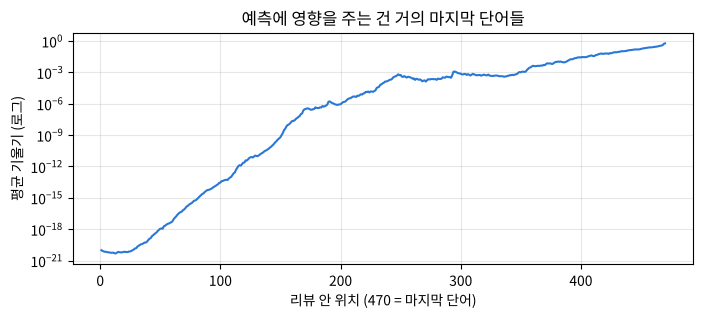

In [14]:
model.eval()
xb = torch.LongTensor(X_test[:200]).to(device)
emb_out = model.embedding(xb)
emb_out.retain_grad()
output, h_n = model.rnn(emb_out)
model.fc(h_n[-1]).sum().backward()                      # 예측 점수를 각 단어 임베딩까지 거꾸로
g = emb_out.grad.norm(dim=2).mean(0).cpu().numpy()      # 시점별 평균 기울기 크기

pos = np.arange(1, MAX_LEN + 1)
print('끝에서 1 · 10 · 50 · 100 · 200 · 470 번째 단어의 기울기 :',
      [f'{g[-k]:.1e}' for k in [1, 10, 50, 100, 200, 470]])
plt.figure(figsize=(8, 3))
plt.semilogy(pos, g, color='#2a78d6'); plt.xlabel('리뷰 안 위치 (470 = 마지막 단어)'); plt.ylabel('평균 기울기 (로그)')
plt.title('예측에 영향을 주는 건 거의 마지막 단어들'); plt.grid(alpha=0.3); plt.show()
model.zero_grad()

교재 p.78 의 BPTT 를 실제 모델에서 잰 것 — 예측 점수의 기울기가 **마지막 수십 단어**에 몰려 있고 앞쪽으로 갈수록 급격히 작아진다. 단순 RNN 은 긴 리뷰의 앞부분을 사실상 잊는다(**장기 의존성 문제**) → LSTM · GRU 가 필요한 이유.

## 9. 예측해 보기

In [15]:
import re

def predict(text):
    ids = [1] + [word_index[w] + 3 if w in word_index and word_index[w] + 3 < NUM_WORDS else 2
                 for w in re.findall(r"[a-z0-9']+", text.lower())]          # 소문자 · 단어만 (IMDB 사전과 같은 방식)
    x = torch.LongTensor(keras.utils.pad_sequences([ids], maxlen=MAX_LEN)).to(device)
    with torch.no_grad():
        return torch.sigmoid(model(x)).item()

for s in ['This movie was wonderful. The acting was great and I loved the story.',
          'Terrible film. Boring plot, bad acting, a complete waste of time.',
          'I expected a great movie but it was disappointing.',
          'The first half was boring, but the ending was amazing and I loved it.']:
    print(f'{predict(s):.3f}  {s}')

0.885  This movie was wonderful. The acting was great and I loved the story.
0.041  Terrible film. Boring plot, bad acting, a complete waste of time.
0.741  I expected a great movie but it was disappointing.
0.732  The first half was boring, but the ending was amazing and I loved it.


In [16]:
# 평가용 리뷰 몇 개 — 확률 · 정답 · 앞부분
with torch.no_grad():
    probs = torch.sigmoid(model(torch.LongTensor(X_test[:6]).to(device))).cpu().numpy()
for p, y, raw in zip(probs, y_test[:6], X_test_raw[:6]):
    mark = '✓' if (p > 0.5) == y else '✗'
    print(f'{mark} 확률 {p:.3f} 정답 {y} | {decode(raw[1:25])} ...')

✓ 확률 0.436 정답 0 | please give this one a miss br br <unk> <unk> and the rest of the cast rendered terrible performances the show is flat flat ...
✓ 확률 0.912 정답 1 | this film requires a lot of patience because it focuses on mood and character development the plot is very simple and many of the ...
✓ 확률 0.715 정답 1 | many animation buffs consider <unk> <unk> the great forgotten genius of one special branch of the art puppet animation which he invented almost single ...
✓ 확률 0.214 정답 0 | i generally love this type of movie however this time i found myself wanting to kick the screen since i can't do that i ...
✓ 확률 0.966 정답 1 | like some other people wrote i'm a die hard mario fan and i loved this game br br this game starts slightly boring but ...
✓ 확률 0.727 정답 1 | i'm absolutely disgusted this movie isn't being sold all who love this movie should email disney and increase the demand for it they'd eventually ...


- 세 번째 문장(`great` 을 기대했지만 `disappointing`)은 부정인데 긍정으로 본다 — 단어 하나하나의 느낌은 잡아도 '기대했지만 실망' 같은 구조는 단순 RNN 이 아직 놓친다.

## 정리

| 단계 | 원본 `nlp_실습07` | 고친 노트 |
|---|---|---|
| 데이터 도구 | `tensorflow` 두 번 import | `keras` 하나 (TensorFlow 없어도 동작) |
| 길이 분석 | 25,000개 길이 전체 출력 | 분위수 · 히스토그램 · 잘리는 비율 |
| 패딩 | `pad_sequences` 기본값 | 기본값 = 앞쪽(pre) 이유 확인 · post 실험 |
| 검증 | 없음 (평가용만) | 학습에서 검증 5,000 분리 |
| 모델 · 학습 · 평가 | 행렬 곱 예제에서 멈춤 | Embedding → RNN → Linear 학습 · 평가 · BPTT 기울기 · 예측 |